## ROBOTICA - PARCIAL 2025-1

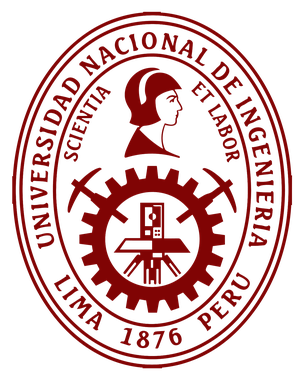

Alumno: Lopez Arteaga, Cesar Omar
Codigo: 20215508C
---

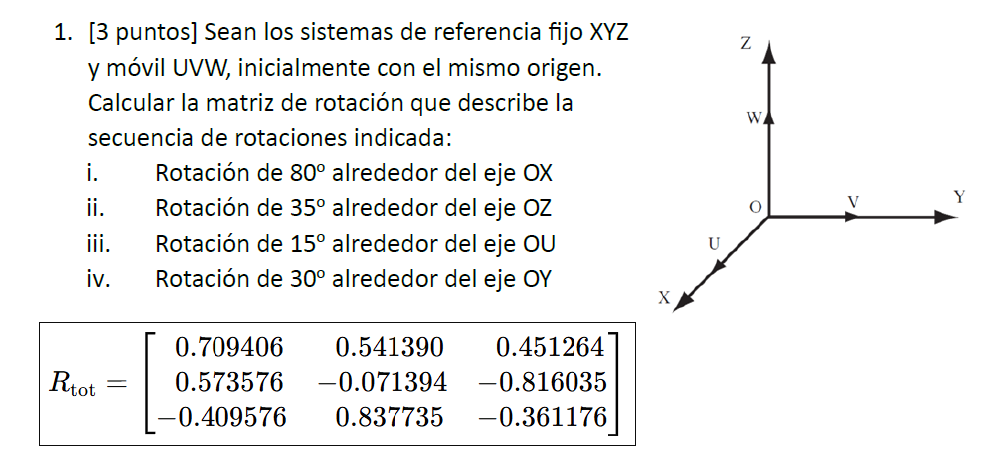

In [1]:
import numpy as np
import sympy as sp
from fquad import *
from homo4 import *
np.set_printoptions(precision=4,suppress=True)

H1=Rx4(80)
H2=Rz4(35)
H3=Rx4(15)
H4=Ry4(30)
H=H4@H2@H1@H3
print("Matriz Homogenea H:")
print(H)
print("\nMatriz de Rotacion R:")
R=H[0:3,0:3]
print(R)



Matriz Homogenea H:
[[ 0.7094  0.5414  0.4513  0.    ]
 [ 0.5736 -0.0714 -0.816   0.    ]
 [-0.4096  0.8377 -0.3612  0.    ]
 [ 0.      0.      0.      1.    ]]

Matriz de Rotacion R:
[[ 0.7094  0.5414  0.4513]
 [ 0.5736 -0.0714 -0.816 ]
 [-0.4096  0.8377 -0.3612]]


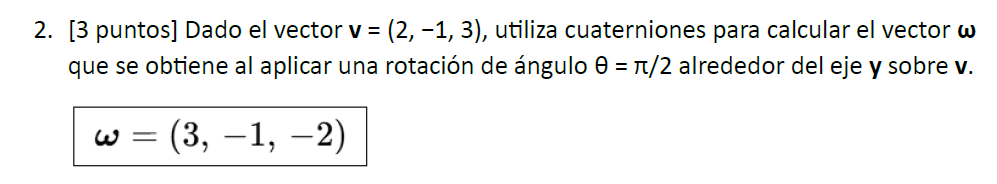

In [2]:
import numpy as np
from fquad import *
np.set_printoptions(precision=4,suppress=True)

v = np.array([2,-1,3]) 
a = np.array([0,1,0])
Q=Rot(a,90)
#ampliamos el cuaternio v a (0, v)
v= np.insert(v, 0, 0)

#impresion de resultados
print("Cuaternio Q de rotacion de 90 alrededor de a")
print("Q =",Q)
print("\nVector v =",v)
w=qprod(qprod(Q,v),qconj(Q))
print("Usando cuaternios completo: w=v'=",w)
print("\nVector  w=",w[1:4])

Cuaternio Q de rotacion de 90 alrededor de a
Q = [0.7071 0.     0.7071 0.    ]

Vector v = [ 0  2 -1  3]
Usando cuaternios completo: w=v'= [ 0.  3. -1. -2.]

Vector  w= [ 3. -1. -2.]


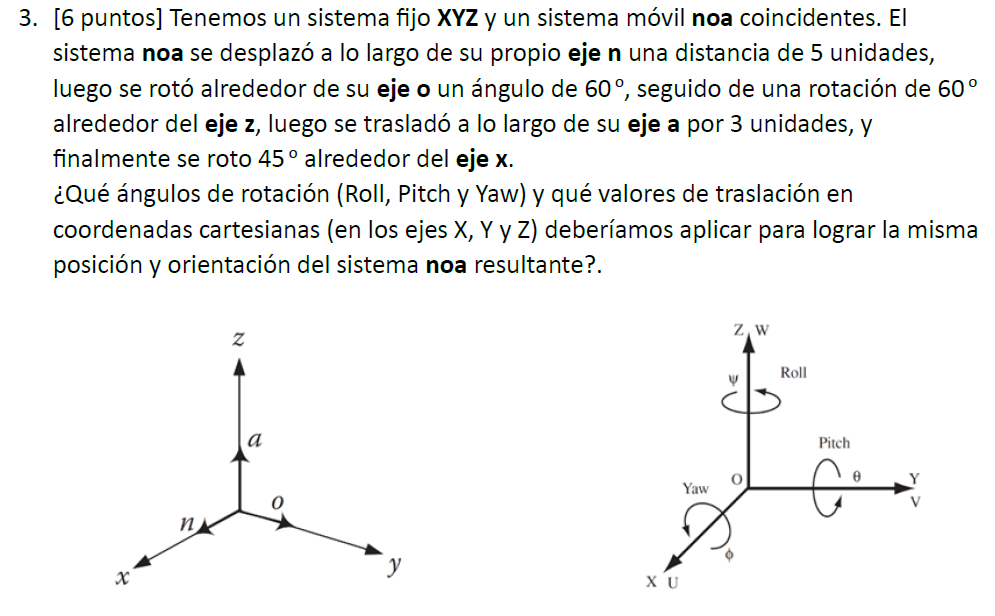

## Solución del problema 3

$$
H_1=T_x(5),\qquad
H_2=R_y(60^\circ),\qquad
H_3=R_z(60^\circ)
$$

$$
H_4=T_z(3),\qquad
H_5=R_x(45^\circ)
$$

$$
\boxed{
H=H_5H_3H_1H_2H_4
}
$$

$$
H=R_x(45^\circ)R_z(60^\circ)T_x(5)R_y(60^\circ)T_z(3)
$$

$$
\boxed{
H=
\begin{bmatrix}
0.250 & -0.866 & 0.433 & 3.799\\
0.919 & 0.354 & 0.177 & 3.592\\
-0.306 & 0.354 & 0.884 & 5.714\\
0 & 0 & 0 & 1
\end{bmatrix}
}
$$

### 1. Vector de traslación

$$
\boxed{
\mathbf{p}=
\begin{bmatrix}
p_x\\
p_y\\
p_z
\end{bmatrix}
=
\begin{bmatrix}
3.799\\
3.592\\
5.714
\end{bmatrix}
}
$$

### 2. Vectores de orientación

$$
H=
\begin{bmatrix}
n_x&o_x&a_x&p_x\\
n_y&o_y&a_y&p_y\\
n_z&o_z&a_z&p_z\\
0&0&0&1
\end{bmatrix}
$$

$$
\mathbf{n}=
\begin{bmatrix}
0.250\\
0.918559\\
-0.306186
\end{bmatrix},
\qquad
\mathbf{o}=
\begin{bmatrix}
-0.866025\\
0.353553\\
0.353553
\end{bmatrix}
$$

$$
\mathbf{a}=
\begin{bmatrix}
0.433013\\
0.176777\\
0.883883
\end{bmatrix}
$$

### 3. Ángulo Yaw

$$
\psi=\operatorname{atan2}(n_y,n_x)
$$

$$
\psi=\operatorname{atan2}(0.918559,0.250)
$$

$$
\boxed{\psi=74.775^\circ}
$$

### 4. Ángulo Pitch

$$
\theta=
\operatorname{atan2}
\left(
-n_z,\,
n_x\cos\psi+n_y\sin\psi
\right)
$$

$$
\theta=
\operatorname{atan2}
\left(
0.306186,\,
0.250\cos74.775^\circ+
0.918559\sin74.775^\circ
\right)
$$

$$
\theta=
\operatorname{atan2}(0.306186,0.951155)
$$

$$
\boxed{\theta=17.830^\circ}
$$

### 5. Ángulo Roll

$$
\phi=
\operatorname{atan2}
\left(
-a_y\cos\psi+a_x\sin\psi,\,
o_y\cos\psi-o_x\sin\psi
\right)
$$

$$
\phi=
\operatorname{atan2}
\left(
-0.176777\cos74.775^\circ
+0.433013\sin74.775^\circ,\,
0.353553\cos74.775^\circ
+0.866025\sin74.775^\circ
\right)
$$

$$
\phi=\operatorname{atan2}(0.371748,0.928334)
$$

$$
\boxed{\phi=21.801^\circ}
$$

### 6. Resultados finales

$$
\boxed{
\begin{aligned}
\text{Roll}\;(\phi)&=21.801^\circ\\
\text{Pitch}\;(\theta)&=17.830^\circ\\
\text{Yaw}\;(\psi)&=74.775^\circ
\end{aligned}
}
$$

$$
\boxed{
\begin{aligned}
p_x&=3.799\\
p_y&=3.592\\
p_z&=5.714
\end{aligned}
}
$$

In [3]:
import numpy as np
import sympy as sp
from fquad import *
from homo4 import *
from rot3D_Sym import *
np.set_printoptions(precision=3,suppress=True)

H1=T4(5,0,0)
H2=Ry4(60)
H3=Rz4(60)
H4=T4(0,0,3)
H5=Rx4(45)

H=H5@H3@H1@H2@H4  
print("Matriz Homogenea H:")
print(H)

print("\nMatriz de translacion T:")
print(H[:3, 3])

n=sp.Matrix(H[:3, 0])
o=sp.Matrix(H[:3, 1])
a=sp.Matrix(H[:3, 2])
print("\nVector n:")
print(n)
print("\nVector o:")
print(o)                
print("\nVector a:")
print(a)

theta = sp.atan2(n[1], n[0])
theta_grados = sp.deg(theta)
print(f"\nAngulo en radianes: {float(theta):.3f}")
print(f"Angulo en grados: {float(theta_grados):.2f}")

phi=sp.atan2(-n[2], sp.sqrt(n[0]**2 + n[1]**2))
phi_grados = sp.deg(phi)
print(f"\nAngulo en radianes: {float(phi):.3f}")
print(f"Angulo en grados: {float(phi_grados):.2f}")

alpha=sp.atan2(o[2], a[2])
alpha_grados = sp.deg(alpha)
print(f"\nAngulo en radianes: {float(alpha):.3f}")  
print(f"Angulo en grados: {float(alpha_grados):.2f}")



Matriz Homogenea H:
[[ 0.25  -0.866  0.433  3.799]
 [ 0.919  0.354  0.177  3.592]
 [-0.306  0.354  0.884  5.714]
 [ 0.     0.     0.     1.   ]]

Matriz de translacion T:
[3.799 3.592 5.714]

Vector n:
Matrix([[0.250000000000000], [0.918558653543692], [-0.306186217847897]])

Vector o:
Matrix([[-0.866025403784439], [0.353553390593274], [0.353553390593274]])

Vector a:
Matrix([[0.433012701892219], [0.176776695296637], [0.883883476483185]])

Angulo en radianes: 1.305
Angulo en grados: 74.77

Angulo en radianes: 0.311
Angulo en grados: 17.83

Angulo en radianes: 0.381
Angulo en grados: 21.80


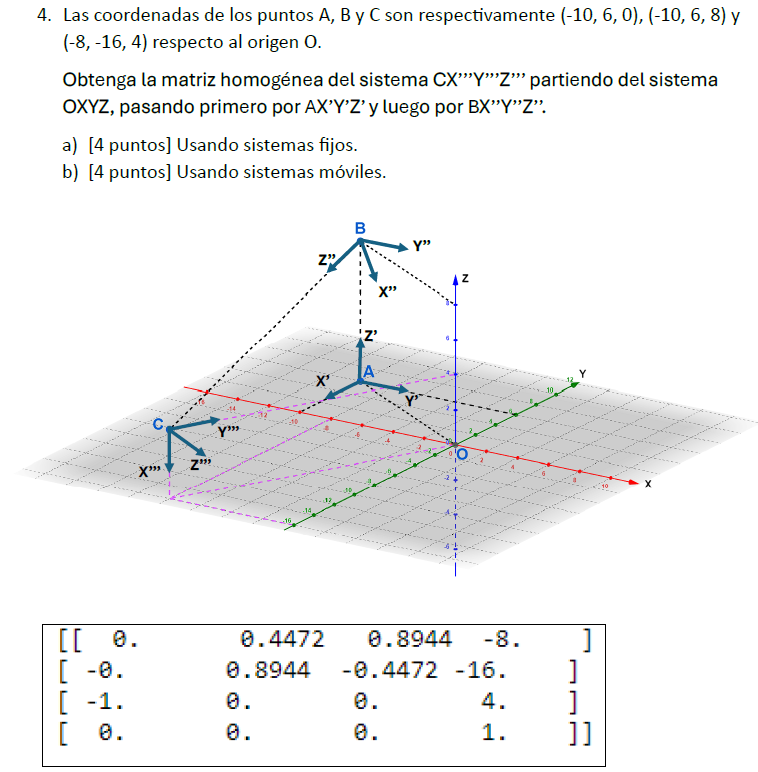


In [ ]:
import numpy as np
from fquad import *
from homo4 import *

np.set_printoptions(precision=4, suppress=True)

A = np.array([-10, 6, 0])
B = np.array([-10, 6, 8])
C = np.array([-8, -16, 4])

# parte b
H1 = T4(-10, 6, 0)
H2 = Rz4(-90)
H3 = T4(0, 0, 8)

v1 = np.array([0, 0, 1])
v2 = C - B

print("\nVector v1 =", v1)
print("Vector v2 = C-B =", v2)

# calcular angulo entre vectores
cos_theta = np.dot(v1, v2) / (
    np.linalg.norm(v1) * np.linalg.norm(v2)
)

angle = np.arccos(np.clip(cos_theta, -1, 1))
angle_deg = np.degrees(angle)

print(f"\nAngulo entre v1 y v2 = {angle_deg:.3f} grados")

# matriz de rotacion
H4 = Ry4(angle_deg)

# matriz homogenea acumulada
TT = H1 @ H2 @ H3 @ H4

print("\nMatriz homogenea TT:")
print(TT)

# inversa de la matriz homogenea
TT_inv = np.linalg.inv(TT)

print("\nMatriz homogenea inversa:")
print(TT_inv)

# coordenadas de C en el sistema local
C_h = np.append(C, 1)
C_local = TT_inv @ C_h

print("\nPunto C en el sistema X'':")
print(C_local[:3])

# matriz de traslacion local
H5 = T4(*C_local[:3])

print("\nMatriz H5:")
print(H5)

# transformacion final
H = TT @ H5

print("\nMatriz homogenea final H:")
print(H)

H6=Ry4(90-angle_deg)
angle2 = np.arctan2(2, 1)
angle2_deg = np.degrees(angle2)

H7=Rx4(angle2_deg)

H_final = H @ H6 @ H7
print("\nMatriz homogenea final H con rotaciones adicionales:")
print(H_final)


Vector v1 = [0 0 1]
Vector v2 = C-B = [  2 -22  -4]

Angulo entre v1 y v2 = 100.263 grados

Matriz homogenea TT:
[[ -0.       1.       0.     -10.    ]
 [  0.1782   0.      -0.984    6.    ]
 [ -0.984    0.      -0.1782   8.    ]
 [  0.       0.       0.       1.    ]]

Matriz homogenea inversa:
[[-0.      0.1782 -0.984   6.8029]
 [ 1.      0.      0.     10.    ]
 [ 0.     -0.984  -0.1782  7.3294]
 [ 0.      0.      0.      1.    ]]

Punto C en el sistema X'':
[ 0.0162  2.     22.3607]

Matriz H5:
[[ 1.      0.      0.      0.0162]
 [ 0.      1.      0.      2.    ]
 [ 0.      0.      1.     22.3607]
 [ 0.      0.      0.      1.    ]]

Matriz homogenea final H:
[[ -0.       1.       0.      -8.    ]
 [  0.1782   0.      -0.984  -16.    ]
 [ -0.984    0.      -0.1782   4.    ]
 [  0.       0.       0.       1.    ]]

Matriz homogenea final H con rotaciones adicionales:
[[  0.       0.4472  -0.8944  -8.    ]
 [ -0.      -0.8944  -0.4472 -16.    ]
 [ -1.       0.       0.       4.    ]